In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score,r2_score,confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier,VotingClassifier
from sklearn.tree import DecisionTreeClassifier,DecisionTreeRegressor
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.ensemble import BaggingClassifier,GradientBoostingClassifier
from xgboost import XGBClassifier

In [ ]:
# 1. Encode Sex
def encode_sex(train, test):
    sex_map = {'male': 0, 'female': 1}
    train['Sex'] = train['Sex'].map(sex_map)
    test['Sex'] = test['Sex'].map(sex_map)
    return train, test
# 2. Encode Embarked using One Hot Encoding
def encode_embarked(train, test):
    mode_value = train['Embarked'].mode()[0]
    train['Embarked'] = train['Embarked'].fillna(mode_value)
    test['Embarked'] = test['Embarked'].fillna(mode_value)
    train = pd.get_dummies(train, columns=['Embarked'], dtype=int)  #1Hot Encoding
    test = pd.get_dummies(test, columns=['Embarked'], dtype=int)    #1Hot Encoding
    # Ensure identical columns
    embarked_cols = ['Embarked_C', 'Embarked_Q', 'Embarked_S']
    train = train.reindex(columns=list(train.columns),fill_value=0)
    test = test.reindex(columns=list(test.columns),fill_value=0)
    for col in embarked_cols:
        if col not in train.columns:
            train[col] = 0
    return train, test
# 3. Fill missing Fare
def fill_fare(train, test):
    fare_median = train['Fare'].median()
    train['Fare'] = train['Fare'].fillna(fare_median)
    test['Fare'] = test['Fare'].fillna(fare_median)
    return train, test
# 4. Predict missing Age using Decision Tree
def impute_age(train, test):
    features = ['Pclass', 'Sex', 'SibSp', 'Parch', 'Fare','Embarked_C', 'Embarked_Q', 'Embarked_S']
    known_age = train[train['Age'].notnull()]
    missing_age = train[train['Age'].isnull()]
    X_age = known_age[features]
    y_age = known_age['Age']
    dt = DecisionTreeRegressor(random_state=42)
    dt.fit(X_age, y_age)
    # Predict missing Age in train
    if not missing_age.empty:
        train.loc[missing_age.index, 'Age'] = dt.predict(missing_age[features])
    # Predict missing Age in test
    missing_test = test['Age'].isnull()
    if missing_test.any():
        test.loc[missing_test,'Age']=dt.predict(test.loc[missing_test, features])
    return train, test, dt
# 5. Main preprocessing function
def preprocess_data(train, test):
    train = train.copy()
    test = test.copy()
    drop_cols = ['Name', 'Ticket', 'Cabin', 'PassengerId']
    train.drop(columns=drop_cols, inplace=True, errors='ignore')
    test.drop(columns=drop_cols, inplace=True, errors='ignore')
    
    # Applying preprocessing functions
    train, test = encode_sex(train, test)
    train, test = encode_embarked(train, test)
    train, test = fill_fare(train, test)
    train, test, age_model = impute_age(train, test)
    return train, test, age_model



Passenger IDs matched successfully
Accuracy: 81.01 %


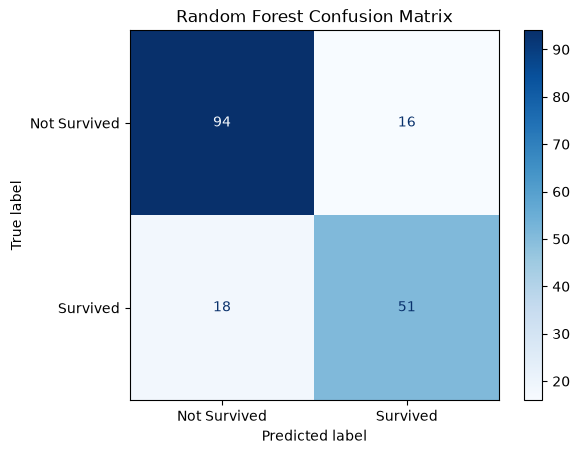

In [ ]:
train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')
test_ids=test['PassengerId'].copy()
y=train['Survived']
train, test, age_model = preprocess_data(train, test)
X_train = train.drop(columns=['Survived'])
X_test = test.copy()
X_test = X_test.reindex(columns=X_train.columns,fill_value=0)
model = XGBClassifier()
model.fit(X_train, y)
y_pred = model.predict(X_test)
#print(y_pred)
submission = pd.read_csv('gender_submission.csv')
submission['Survived'] =y_pred
if list(submission['PassengerId'])==list(test_ids):
    print("Passenger IDs matched successfully")
else:
    print("Passenger IDs do not match")
submission.to_csv('my_submission.csv',index=False)
#print(submission.head())
#Checking Accuracy & Confusion Matrix
X = train.drop('Survived', axis=1)
y = train['Survived']
X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
model = XGBClassifier()
model.fit(X_train, y_train)
y_pred = model.predict(X_val)
accuracy = accuracy_score(y_val, y_pred)
print("Accuracy:", round(accuracy * 100, 2), "%")
cm = confusion_matrix(y_val, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=['Not Survived', 'Survived'])
disp.plot(cmap='Blues', values_format='d')
plt.title('Random Forest Confusion Matrix')
plt.show()


In [ ]:

gender = pd.read_csv('gender_submission.csv')
my = pd.read_csv('my_submission.csv')
accuracy = accuracy_score(
    gender['Survived'],
    my['Survived']
)
print("Agreement Score:", round(accuracy * 100, 2), "%")

Agreement Score: 82.78 %
